#Imports

In [82]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, LabelEncoder
from sklearn.impute import SimpleImputer
from imblearn.over_sampling import SMOTE

In [83]:
df = pd.read_csv("/content/sample_data/adult_dataset (1).csv")

In [84]:
print(df.shape)
print('-'*40)
print(df.dtypes)
print('-'*40)
print(df.describe())
print('-'*40)
print(df.isna().sum())
print('-'*40)
print(df.duplicated().sum())
print('-'*40)
print(df.value_counts())

(48842, 15)
----------------------------------------
age               float64
workclass          object
fnlwgt              int64
education          object
education-num       int64
marital-status     object
occupation         object
relationship       object
race               object
sex                object
capital-gain        int64
capital-loss        int64
hours-per-week    float64
native-country     object
income             object
dtype: object
----------------------------------------
                age        fnlwgt  education-num  capital-gain  capital-loss  \
count  46400.000000  4.884200e+04   48842.000000  48842.000000  48842.000000   
mean      38.679116  1.896641e+05      10.078089   1079.067626     87.502314   
std       13.952954  1.056040e+05       2.570973   7452.019058    403.004552   
min       17.000000  1.228500e+04       1.000000      0.000000      0.000000   
25%       28.000000  1.175505e+05       9.000000      0.000000      0.000000   
50%       37.000000  1

In [85]:
df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39.0,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40.0,NaN,<=50K
1,50.0,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13.0,United-States,<=50K
2,38.0,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40.0,United-States,<=50K
3,53.0,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40.0,United-States,<=50K
4,28.0,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40.0,Cuba,<=50K


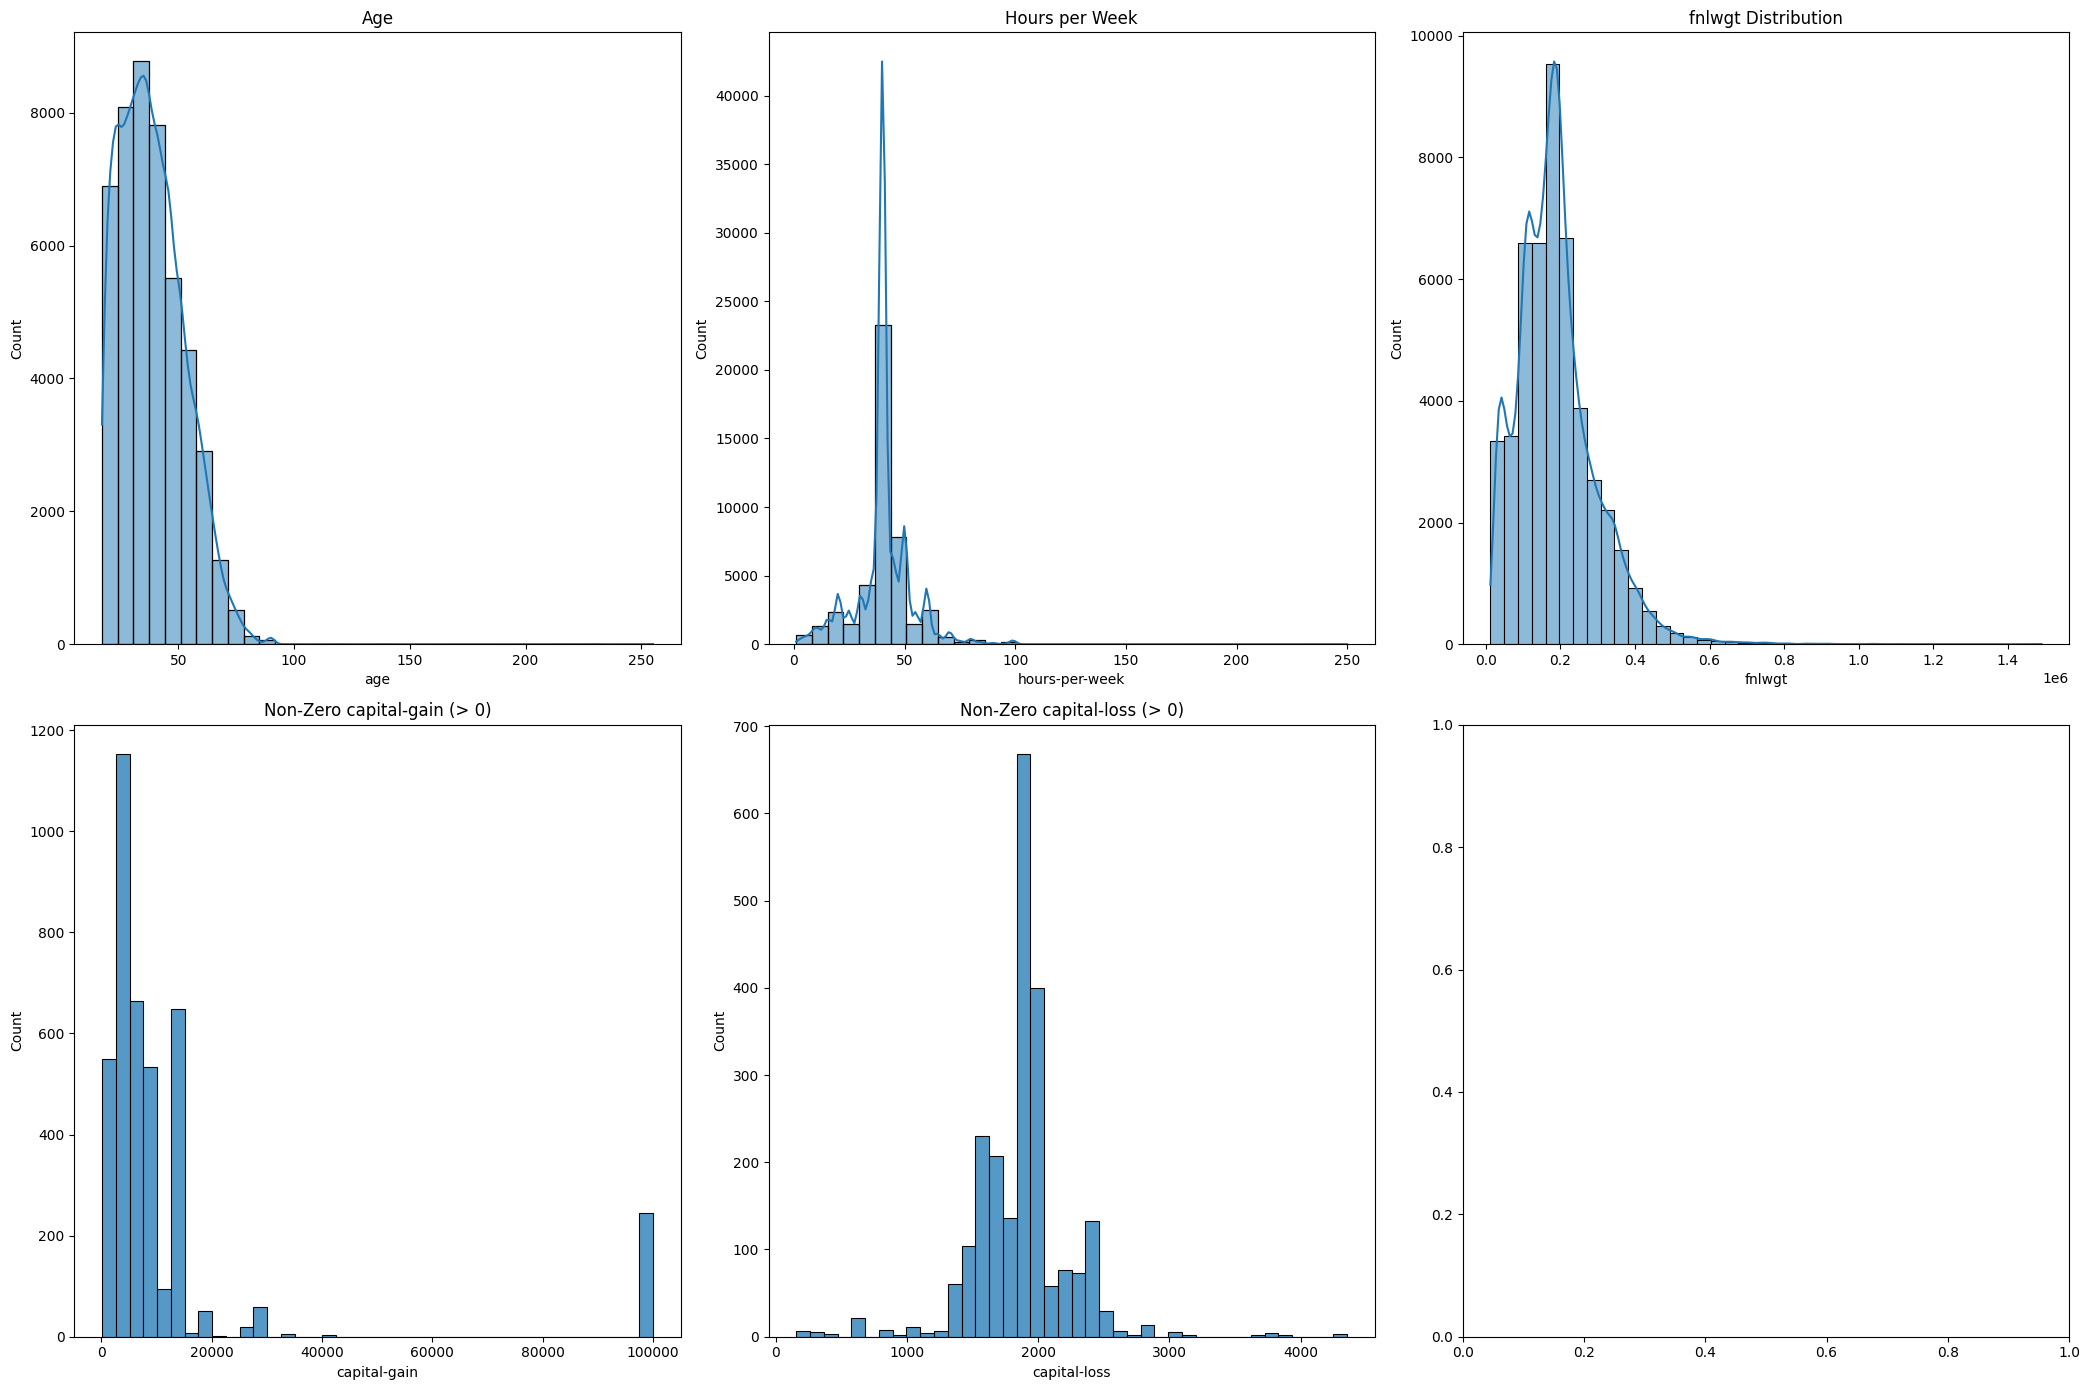

In [86]:
fig, axes = plt.subplots(2, 3, figsize=(21, 14))

sns.histplot(df["age"].dropna(), bins=35, kde=True, ax=axes[0, 0])
axes[0, 0].set_title("Age")

sns.histplot(df["hours-per-week"].dropna(), bins=35, kde=True, ax=axes[0, 1])
axes[0, 1].set_title("Hours per Week")

sns.histplot(df["fnlwgt"], bins=40, kde=True, ax=axes[0, 2])
axes[0, 2].set_title("fnlwgt Distribution")

sns.histplot(df[df["capital-gain"] > 0]["capital-gain"], bins=40, kde=False, ax=axes[1, 0])
axes[1, 0].set_title("Non-Zero capital-gain (> 0)")

sns.histplot(df[df["capital-loss"] > 0]["capital-loss"], bins=40, kde=False, ax=axes[1, 1])
axes[1, 1].set_title("Non-Zero capital-loss (> 0)")

plt.tight_layout()
plt.show()

In [87]:
df["income"] = df["income"].astype(str).str.strip().str.rstrip(".")
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].replace("?", np.nan)

df = df.drop(columns=["education"])

removes trailing dot in income , replacing `"?"` with `np.nan` standardizes missing categories, and dropping `education` removes an exact text duplicate of `education-num`.

In [88]:
print(df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print(df.duplicated().sum())

29
0


In [89]:
print("Rows with age > 100:", (df["age"] > 100).sum())
print("Rows with hours-per-week > 100:", (df["hours-per-week"] > 100).sum())

impossible = (df["age"].notna() & (df["age"] > 100)) | (df["hours-per-week"].notna() & (df["hours-per-week"] > 100))

df = df[~impossible].reset_index(drop=True)


Rows with age > 100: 9
Rows with hours-per-week > 100: 10


Rows with age or hours-per-week above 100  are errors and removed

In [90]:
X = df.drop(columns=["income"])
y = df["income"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

Splitting prevents data leakage

Stratify preserves the class distribution

In [91]:
le = LabelEncoder()
y_train = pd.Series(le.fit_transform(y_train), index=y_train.index, name="income")
y_test = pd.Series(le.transform(y_test), index=y_test.index, name="income")


LabelEncoder fit on y_train and only transform on y_test.

In [92]:
num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = X_train.select_dtypes(include="object").columns.tolist()

num_imputer = SimpleImputer(strategy="median")
X_train_num = pd.DataFrame(
    num_imputer.fit_transform(X_train[num_cols]),
    columns=num_cols,
    index=X_train.index
)
X_test_num = pd.DataFrame(
    num_imputer.transform(X_test[num_cols]),
    columns=num_cols,
    index=X_test.index
)


 Median imputation on right skewed numeric columns

In [93]:
cat_imputer = SimpleImputer(strategy="most_frequent")
X_train_cat = pd.DataFrame(
    cat_imputer.fit_transform(X_train[cat_cols]),
    columns=cat_cols,
    index=X_train.index
)
X_test_cat = pd.DataFrame(
    cat_imputer.transform(X_test[cat_cols]),
    columns=cat_cols,
    index=X_test.index
)

Most-frequent imputation on categorical columns.

In [94]:
ohe_cols = ["native-country","workclass", "marital-status", "occupation", "relationship", "race", "sex"]
ohe = OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore")
X_train_ohe = pd.DataFrame(
    ohe.fit_transform(X_train_cat[ohe_cols]),
    columns=ohe.get_feature_names_out(ohe_cols),
    index=X_train.index
)
X_test_ohe = pd.DataFrame(
    ohe.transform(X_test_cat[ohe_cols]),
    columns=ohe.get_feature_names_out(ohe_cols),
    index=X_test.index
)

One Hot Encoding on categorical columns with no ordering.

In [95]:
X_train_comb = pd.concat([X_train_num, X_train_ohe], axis=1)
X_test_comb = pd.concat([X_test_num, X_test_ohe], axis=1)


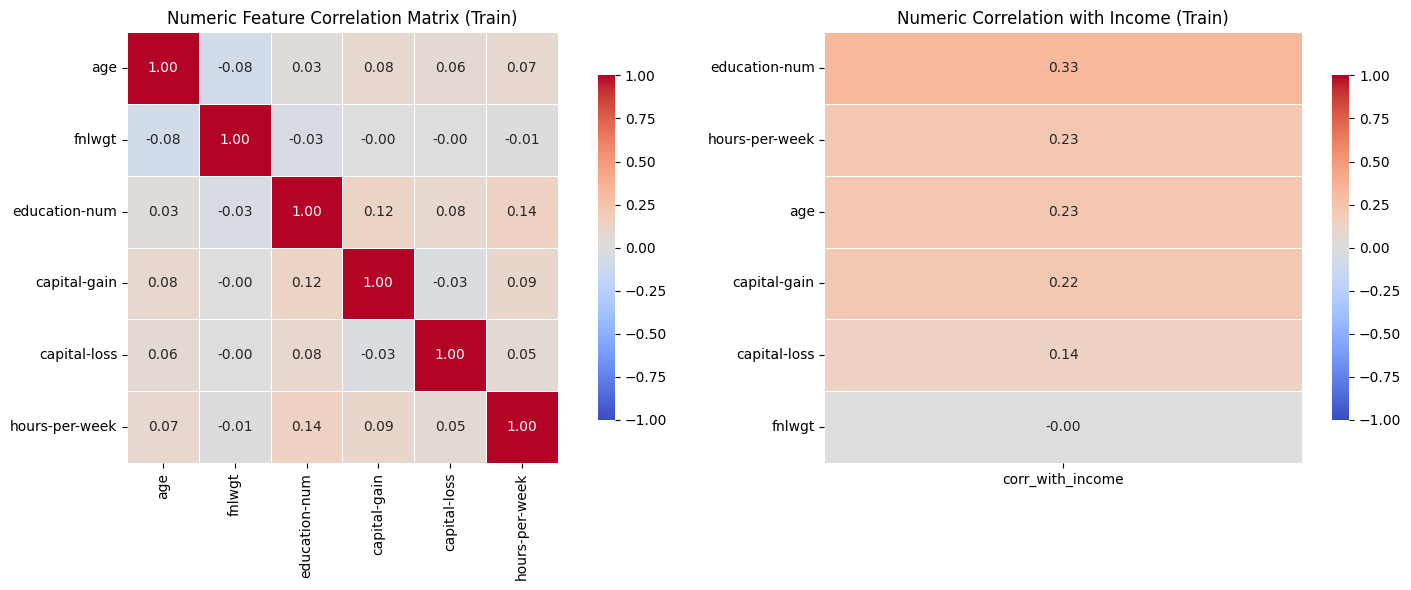

In [96]:
num_train = X_train.select_dtypes(include="number").copy()
corr_num = num_train.corr()
corr_with_y = num_train.apply(lambda s: s.corr(y_train)).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1.35, 1]})

sns.heatmap(
    corr_num,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8},
    ax=axes[0],
)
axes[0].set_title("Numeric Feature Correlation Matrix (Train)")

sns.heatmap(
    corr_with_y.to_frame(name="corr_with_income"),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8},
    ax=axes[1],
)
axes[1].set_title("Numeric Correlation with Income (Train)")

plt.tight_layout()
plt.show()

correlations shows education-num, hours-per-week, age, and capital-gain as top numeric signals.

In [97]:
variances = X_train_comb.var(axis=0)
kept_cols = variances[variances >= 0.01].index.tolist()
print("Dropped low-variance (< 0.01) columns:", variances[variances < 0.01].index.tolist())

X_train_vt = X_train_comb[kept_cols].copy()
X_test_vt = X_test_comb[kept_cols].copy()

Dropped low-variance (< 0.01) columns: ['native-country_Canada', 'native-country_China', 'native-country_Columbia', 'native-country_Cuba', 'native-country_Dominican-Republic', 'native-country_Ecuador', 'native-country_El-Salvador', 'native-country_England', 'native-country_France', 'native-country_Germany', 'native-country_Greece', 'native-country_Guatemala', 'native-country_Haiti', 'native-country_Holand-Netherlands', 'native-country_Honduras', 'native-country_Hong', 'native-country_Hungary', 'native-country_India', 'native-country_Iran', 'native-country_Ireland', 'native-country_Italy', 'native-country_Jamaica', 'native-country_Japan', 'native-country_Laos', 'native-country_Nicaragua', 'native-country_Outlying-US(Guam-USVI-etc)', 'native-country_Peru', 'native-country_Philippines', 'native-country_Poland', 'native-country_Portugal', 'native-country_Puerto-Rico', 'native-country_Scotland', 'native-country_South', 'native-country_Taiwan', 'native-country_Thailand', 'native-country_Trin

In [98]:
scale_cols = [
    "age",
    "fnlwgt",
    "education-num",
    "capital-gain",
    "capital-loss",
    "hours-per-week",
]
scale_cols = [c for c in scale_cols if c in X_train_vt.columns and c in X_test_vt.columns]
scaler = StandardScaler()
X_train_sc = pd.DataFrame(
    scaler.fit_transform(X_train_vt[scale_cols]),
    columns=scaler.feature_names_in_,
    index=X_train_vt.index,
)
X_test_sc = pd.DataFrame(
    scaler.transform(X_test_vt[scaler.feature_names_in_]),
    columns=scaler.feature_names_in_,
    index=X_test_vt.index,
)

Filtering variance `< 0.01` before scaling drops near-constant dummy columns, and fitting `StandardScaler` only on non-binary features leaves `0`/`1` binary columns and `y` unscaled.

In [99]:
binary_cols = [c for c in kept_cols if set(X_train_vt[c].dropna().unique()).issubset({0, 1, 0.0, 1.0})]
X_train_final = pd.concat([X_train_sc, X_train_vt[binary_cols]], axis=1)
X_test_final = pd.concat([X_test_sc, X_test_vt[binary_cols]], axis=1)

In [100]:
smote = SMOTE(random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train_final, y_train)

Applying `SMOTE` strictly to the training split balances the `<=50K` and `>50K` classes while keeping the test split untouched for evaluation.

In [101]:
print("X_train_bal shape:", X_train_bal.shape, "| y_train_bal shape:", y_train_bal.shape)
print("y_train_bal counts:\n", pd.Series(y_train_bal).value_counts())
print("X_test_final shape:", X_test_final.shape, "| y_test shape:", y_test.shape)
print("Missing values (train/test):", X_train_bal.isna().sum().sum(), X_test_final.isna().sum().sum())

X_train_bal shape: (59386, 38) | y_train_bal shape: (59386,)
y_train_bal counts:
 income
0    29693
1    29693
Name: count, dtype: int64
X_test_final shape: (9761, 38) | y_test shape: (9761,)
Missing values (train/test): 0 0
